# Llama 2 in expex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidesartor/expex/blob/ccr-9d70e555-krj2ct/examples/notebooks/llama.ipynb)

> **Python 3.14+ is needed.** expex requires Python 3.14, and Colab's hosted runtimes ship
> Python 3.12 (the 2026.01 runtime has 3.12.12), so on a hosted runtime the setup cell stops
> with a message. To run this notebook in Colab, start Jupyter on Python 3.14 on your machine
> and use *Connect → Connect to a local runtime*
> ([how](https://github.com/davidesartor/expex/blob/ccr-9d70e555-krj2ct/examples/notebooks/README.md#running-in-colab)),
> or open it in Jupyter directly. If *Runtime → Change runtime type* offers a runtime with
> Python 3.14, that works too. The outputs below are from a run on a CPU.

A port of [llama-2-jax](https://github.com/ayaka14732/llama-2-jax) (pure JAX) to expex:
[`examples/llama/llama.py`](../llama/llama.py), 101 lines of code in one file against the
original's 478 across 15. Every module states its sizes (`Attention[D, G, R, K]`: width `D`,
`G` groups of `R` query heads sharing a key/value head of size `K`), heads are contracted by
axis name, and one code path serves training and generation: a forward pass is a pass over an
empty KV cache.

This notebook runs it on a small model, shows what expex reads from the annotations, checks it
against the original's saved outputs, and times it.

In [1]:
# Setup: install expex from GitHub (or use a local checkout) and fetch the examples.
EXPEX_REF = "ccr-9d70e555-krj2ct"  # the branch or tag of github.com/davidesartor/expex to install

import os, pathlib, subprocess, sys

if sys.version_info < (3, 14):
    raise RuntimeError(
        f"expex needs Python 3.14+, and this runtime has Python {sys.version.split()[0]}: "
        "connect to a local runtime with Python 3.14 (see the note at the top of the notebook)"
    )


def find_checkout() -> pathlib.Path | None:
    """A local checkout of expex: $EXPEX_REPO, or a folder above the working directory."""
    if os.environ.get("EXPEX_REPO"):
        return pathlib.Path(os.environ["EXPEX_REPO"]).resolve()
    for folder in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (folder / "src" / "expex").is_dir() and (folder / "examples").is_dir():
            return folder
    return None


def run(*cmd: str) -> None:
    subprocess.run(cmd, check=True)


REPO = find_checkout()
if REPO is None:  # Colab, or a notebook opened on its own: install from GitHub
    REPO = pathlib.Path("expex").resolve()
    run(sys.executable, "-m", "pip", "install", "-q", f"git+https://github.com/davidesartor/expex@{EXPEX_REF}")
    if not REPO.exists():  # the examples and the reference outputs of the originals
        run("git", "clone", "-q", "--depth", "1", "--branch", EXPEX_REF, "https://github.com/davidesartor/expex", str(REPO))
else:
    try:
        import expex  # noqa: F401
    except ImportError:
        run(sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO))
sys.path.insert(0, str(REPO / "examples" / "llama"))
print("examples from", REPO)

examples from .


In [2]:
import inspect
import time

import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np

import expex
import llama  # examples/llama/llama.py
from llama import Llama

print(inspect.getsource(llama.Attention))

@expex.struct
class Attention[D, G, R, K]:
    """Grouped-query attention: G groups of R query heads, each group sharing one key/value head."""

    wq: f32[D, G, R, K] = normal
    wk: f32[D, G, K] = normal
    wv: f32[D, G, K] = normal
    wo: f32[G, R, K, D] = normal

    def __call__[T, S](self, x: f32[T, D], at: Int[T], cache: Cache[G, S, K]) -> tuple[f32[T, D], Cache[G, S, K]]:
        """T tokens at positions `at`, each attending to the cached positions up to its own."""
        assert K % 2 == 0 and T <= S  # K: for the rotary embedding
        q: f32[G, R, T, K] = rope(expex.einsum(x, self.wq, to=(G, R, T, K)), at)  # mapped over G, R
        k = rope(expex.einsum(x, self.wk, to=(G, T, K)), at)
        cache = cache.write(k, expex.einsum(x, self.wv, to=(G, T, K)), at[0])
        visible = jnp.arange(S) <= at[:, None]  # causal, and only positions written so far
        scores: f32[G, R, T, S] = jnp.where(visible, expex.einsum(q, cache.k, to=(G, R, T, S)) / jnp.sqrt(K), -jnp.in

## The annotated signatures

Every typed function and method in the module, as expex reads it. `expex.prove` lists them,
and proves each one for all sizes (below).

In [3]:
def signature(f):
    owner = f.name.rpartition(".")[0]
    return f"{owner}.{f.signature}" if owner else f.signature


for report in expex.prove(llama):
    print(signature(report.fn))

RMSNorm.__call__(self: RMSNorm, x: f32[D]) -> f32[D]
rope[T, K](x: f32[T, K], at: Int[T]) -> f32[T, K]
Cache.write[T](self: Cache, k: f32[G, T, K], v: f32[G, T, K], start: Int[()]) -> Cache[G, S, K]
Attention.__call__[T, S](self: Attention, x: f32[T, D], at: Int[T], cache: Cache[G, S, K]) -> tuple[f32[T, D], Cache[G, S, K]]
MLP.__call__(self: MLP, x: f32[D]) -> f32[D]
Block.__call__[T, S](self: Block, x: f32[T, D], at: Int[T], cache: Cache[G, S, K]) -> tuple[f32[T, D], Cache[G, S, K]]
Llama.__call__[T](self: Llama, tokens: Int[T]) -> f32[T, V]
Llama.empty(self: Llama, S: int) -> list[Cache[G, S, K]]
Llama.extend[T, S](self: Llama, tokens: Int[T], start: Int[()], caches: list[Cache[G, S, K]]) -> tuple[f32[T, D], list[Cache[G, S, K]]]
Llama.loss[T](self: Llama, tokens: Int[T]) -> f32[()]
Llama.generate[T](self: Llama, prompt: Int[T], n: int) -> Int[T + n]


`expex.debug.shapes` shows the shape of every line, for all sizes at once:

In [4]:
print(expex.debug.shapes(llama.Attention.__call__))

__call__[T, S](self: Attention, x: f32[T, D], at: Int[T], cache: Cache[G, S, K]) -> tuple[f32[T, D], Cache[G, S, K]]   [symbolic D, G, K, R, S, T]
   73 |     def __call__[T, S](self, x: f32[T, D], at: Int[T], cache: Cache[G, S, K]) -> tuple[f32[T, D], Cache[G, S, K]]:
   74 |         """T tokens at positions `at`, each attending to the cached positions up to its own."""
   75 |         assert K % 2 == 0 and T <= S  # K: for the rotary embedding
   76 |         q: f32[G, R, T, K] = rope(expex.einsum(x, self.wq, to=(G, R, T, K)), at)  # mapped over G, R   # q: f32[G, R, T, K]
   77 |         k = rope(expex.einsum(x, self.wk, to=(G, T, K)), at)               # k: f32[G, T, K]
   78 |         cache = cache.write(k, expex.einsum(x, self.wv, to=(G, T, K)), at[0])   # cache: Cache(k=f32[G, S, K], v=f32[G, S, K])
   79 |         visible = jnp.arange(S) <= at[:, None]  # causal, and only positions written so far   # visible: Bool[T, S]
   80 |         scores: f32[G, R, T, S] = jnp.where(visibl

## Run it

A small model: vocabulary 100, width 64, 8 query heads in 2 groups sharing 2 key/value heads,
3 layers. The model is built from its annotations: a key, then the sizes. It is written for one
sequence, so a batch of sequences maps over the rows.

In [5]:
model = Llama(jr.key(0), V=100, D=64, F=172, G=2, R=4, K=8, layers=3)
tokens = jr.randint(jr.key(1), (16, 24), 0, 100)  # 16 sequences of 24 tokens

print("logits", model(tokens[0]).shape, "for one sequence;", model(tokens).shape, "for the batch")


@expex.fn(jit=True, donate="auto")
def step[B, T](model: Llama, batch: expex.Int[B, T]) -> tuple[Llama, expex.f32]:
    loss, grads = jax.value_and_grad(lambda m: m.loss(batch).mean())(model)
    return jax.tree.map(lambda p, g: p - 0.5 * g, model, grads), loss


for i in range(5):
    model, loss = step(model, tokens)
    print(f"step {i}: loss {float(loss):.4f}")
print("generated", model.generate(tokens[0, :8], 8))

logits (24, 100) for one sequence; (16, 24, 100) for the batch


step 0: loss 4.6158
step 1: loss 4.4442
step 2: loss 4.4419
step 3: loss 4.3823
step 4: loss 4.3741


generated [96 27 40 53 68 84 38 81 76 60  9 61  2 60 11 11]


## What the annotations give

**Proofs** for every size, without data:

In [6]:
expex.prove(llama)

ok    llama.RMSNorm.__call__
ok    llama.rope
ok    llama.Cache.write
ok    llama.Attention.__call__
ok    llama.MLP.__call__
ok    llama.Block.__call__
ok    llama.Llama.__call__
ok    llama.Llama.empty
ok    llama.Llama.extend
ok    llama.Llama.loss
ok    llama.Llama.generate

11 functions: 11 proved

**A summary** of the model: parameters, bytes and FLOPs per module, with their formulas.

In [7]:
expex.summary(model, T=24)

Llama   (T=24, V=100, D=64, F=172, G=2, R=4, K=8, L=3)
module       class                                    params  formula                                                  bytes   flops  flops formula
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
embed        f32[V, D]                                 6,400  V·D                                                    25.6 kB
layers[*]    Block[D=64, F=172, G=2, R=4, K=8]  × 3   43,392  2·D·G·R·K + 2·D·G·K + 3·D·F + 2·D                       174 kB  2.29 M  4·T·D·G·R·K + 4·S·T·G·R·K + 7·S·T·G·R + 4·T·D·G·K + 4·T·G·R·K + 6·T·D·F + 4·T·G·K + T·G·R + 10·T·D + 6·T·K + 3·T·F + S·T + 34·K + 6·T + 2·S + 48
  attn_norm  RMSNorm[D=64]                                64  D                                                        256 B     259  4·D + 3
    weight   f32[D]                                       64  D                                        

**Cost** as formulas in the sizes, or as numbers for given sizes (here a 7B-like width):

In [8]:
print(expex.cost(Llama.__call__))
print(expex.cost(Llama.__call__, T=4096, V=32000, D=4096, F=11008, G=32, R=1, K=128, layers=32))

Llama.__call__   (sizes: T, V, D, F, G, R, K, L)
  flops        4·T·D·G·R·K·L + 4·T²·G·R·K·L + 7·T²·G·R·L + 4·T·D·G·K·L + 4·T·G·R·K·L + 6·T·D·F·L + 4·T·G·K·L + T·G·R·L + 10·T·D·L + 6·T·K·L + 3·T·F·L + 2·T·V·D + T²·L + 34·K·L + 8·T·L + 4·T·D + 48·L + 9·T
  parameters   2·D·G·R·K·L + 2·D·G·K·L + 3·D·F·L + 2·V·D + 2·D·L + D
  largest      f32[G,R,K,T] (T·G·R·K elements)
  note: L = len(self.layers)
Llama.__call__   (sizes: T=4096, V=32000, D=4096, F=11008, G=32, R=1, K=128, L=32)
  flops        63056232232448   = 63.1 TFLOP
  parameters   6738415616   = 6.74 G
  largest      f32[G,R,K,T] (16777216 elements)
  note: L = len(self.layers)


**A diagram** drawn from the code. When you run the notebook it is an interactive page: click a
call to open it, hover for its signature.

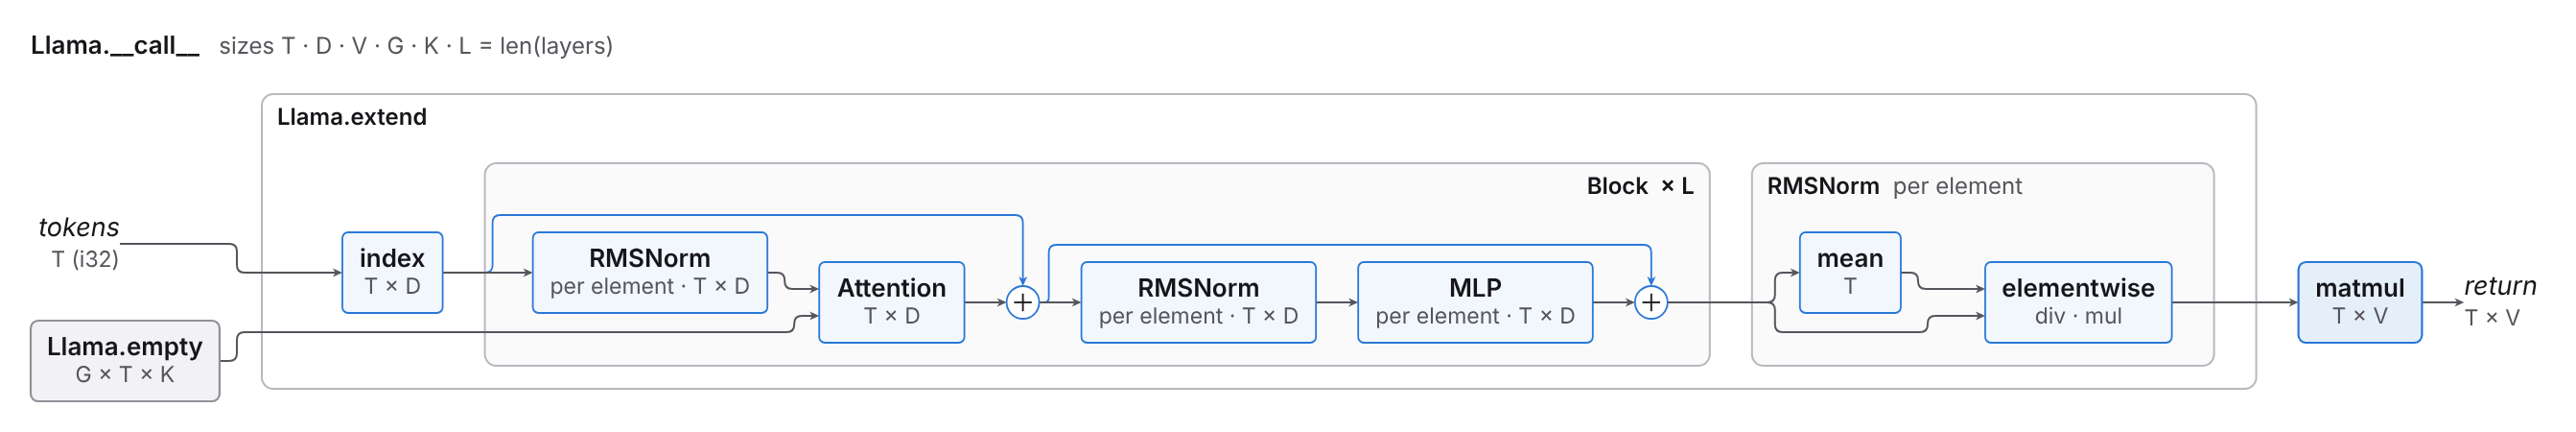

In [9]:
expex.diagram(Llama.__call__, depth=3)

**`expex.inspect`** puts every tool in one page, over the module tree: summary, diagram, cost,
activations and gradients of a loss, and the FLOPs per source line.

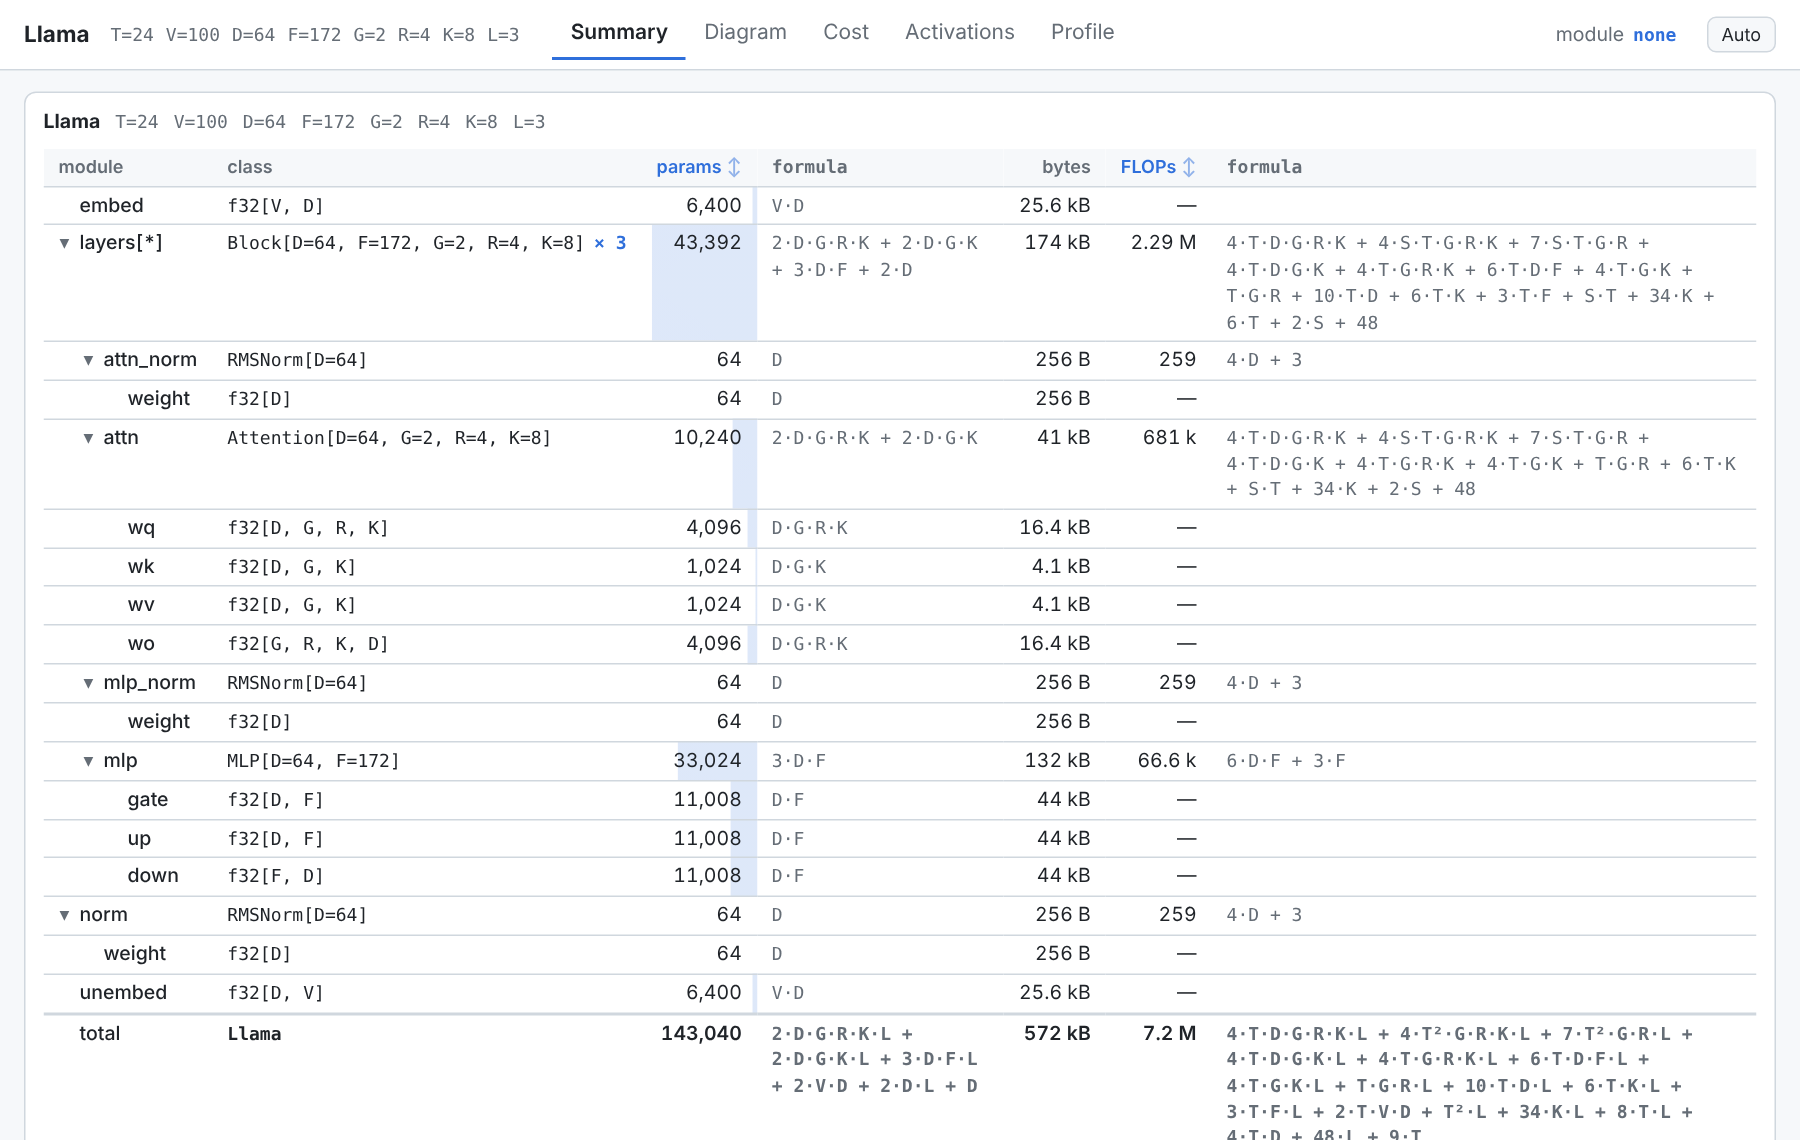

In [10]:
expex.inspect(model, tokens[0], loss=lambda m, t: m.loss(t))

## A shape error

A cache shorter than the tokens written into it breaks `T <= S`, stated in `extend`'s
signature. The error says which constraint, with the sizes it saw:

In [11]:
try:
    model.extend(tokens[0, :12], 0, model.empty(8))
except expex.ShapeError as e:
    error = e
error

ShapeError: Llama.extend(): constraint `T <= S` is violated (S=8, T=12).

    extend[T, S](self: Llama, tokens: Int[T], start: Int[()], caches: list[Cache[G, S, K]]) -> tuple[f32[T, D], list[Cache[G, S, K]]]
    defined at examples/llama/llama.py:129
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex104


And a layer given activations one feature short says where its width came from:

In [12]:
try:
    model.layers[0](jnp.ones((4, 63)), jnp.arange(4), model.empty(8)[0])
except expex.ShapeError as e:
    error = e
error

ShapeError: Block.__call__(): argument `x` does not match its annotation.

    declared  x: f32[T, D]
    received     f32[4, 63]

    D is 64 (from `self.attn_norm.weight: f32[64]`), but axis 1 of `x` is 63.

    __call__[T, S](self: Block, x: f32[T, D], at: Int[T], cache: Cache[G, S, K]) -> tuple[f32[T, D], Cache[G, S, K]]
    defined at examples/llama/llama.py:105
  see https://github.com/davidesartor/expex/blob/main/docs/errors.md#ex101


## Activations and gradients, layer by layer

`expex.debug.watch` runs one forward and backward pass and reports every typed call. Here one
MLP's weights are scaled by 1000 to plant a problem, and the rows it affects are flagged.

In [13]:
broken = model.at.layers[1].mlp.down.multiply(1e3)
watch = expex.debug.watch(lambda m: m.loss(tokens[0]), broken)
for row in watch.flagged:
    print(f"{row.name:32} {'; '.join(row.flags)}")

layers[0].__call__               gradient exploding: RMS 1e+02× the layers' median
layers[0].mlp.__call__           gradient exploding: RMS 1e+02× the layers' median
layers[1].__call__               activations growing: RMS ×24 from layers[0].__call__
layers[1].mlp.__call__           activations growing: RMS ×9.8e+02 from layers[0].mlp.__call__
rope#4                           gradient vanishing: RMS 1/1.4e+02 of the layers' median
rope#5                           gradient vanishing: RMS 1/1.1e+02 of the layers' median
layers[2].mlp_norm.__call__      gradient vanishing: RMS 1/1e+02 of the layers' median


## Against the original

`tests/data/llama_reference.npz` holds the parameters of a small model built by the unmodified
llama-2-jax, its logits, the gradients of a loss and the tokens its own generation loop picks
greedily with the KV cache (written by [`run_original.py`](../llama/run_original.py)).
`compare.py` loads those parameters into the port and measures the largest differences:

In [14]:
import compare  # examples/llama/compare.py

reference = dict(np.load(REPO / "tests" / "data" / "llama_reference.npz"))
for name, diff in compare.compare(reference).items():
    print(f"{name:28} {diff:.3g}")

logits                       7.15e-07
loss                         0
gradients (relative)         6.96e-07
generated tokens differing   0


## Speed

Compiled forward pass, gradients and generation at the small size above. Timings depend on the
machine (a Colab CPU is slower than a laptop), so compare them only with each other. The
repository's [benchmarks/](../../benchmarks/) compare the port with the original: 1.3x forward
and gradients on CPU.

In [15]:
def bench(f, *args, n=20):
    """Median seconds per call, after a first call that compiles."""
    jax.block_until_ready(f(*args))
    times = []
    for _ in range(n):
        start = time.perf_counter()
        jax.block_until_ready(f(*args))
        times.append(time.perf_counter() - start)
    return float(np.median(times))


forward = jax.jit(lambda m, t: m(t))
grads = jax.jit(jax.grad(lambda m, t: m.loss(t).mean()))
print(f"forward, 16 x 24 tokens   {bench(forward, model, tokens) * 1e3:7.2f} ms")
print(f"gradients, 16 x 24 tokens {bench(grads, model, tokens) * 1e3:7.2f} ms")
print(f"generate 8 tokens         {bench(model.generate, tokens[0, :8], 8) * 1e3:7.2f} ms")

forward, 16 x 24 tokens      3.50 ms


gradients, 16 x 24 tokens   10.93 ms


generate 8 tokens            0.98 ms
